<h1><center>Recommender Systems YSDA Course!</center></h1>
<h1>Семинар №1</h1>

<img src="https://i.postimg.cc/gkYSGMkN/content.webp" width="800" />

В этом семинаре мы познакомимся с парочкой датасетов. Построим свои первые рекомендательные системы, а так же попробуем оценить их качество.

In [ ]:
import os
import zipfile
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import requests
from bs4 import BeautifulSoup
from PIL import Image
from scipy.sparse import csr_matrix
from tensorboard.plugins import projector
from tqdm.auto import tqdm

## MovieLens

Датасет с оценками Фильмов

[Dataset](https://grouplens.org/datasets/movielens)

[IMDb.com](https://www.imdb.com)

<img src="https://storage.googleapis.com/kaggle-datasets-images/7089412/11333209/6a0b861f2ee1e5ae95abe1555e26e1b4/dataset-card.png?t=2025-04-09-01-18-47" width="500" />

### Загрузка датасета:

In [ ]:
def download_and_extract(url: str, filename: str, chunk_size: int = 1024):
    if not zipfile.is_zipfile(filename):
        temporary_filename = filename + ".part"
        with requests.get(url, stream=True) as response:
            response.raise_for_status()
            total_size = int(response.headers.get("content-length", 0))
            with open(temporary_filename, "wb") as f, tqdm(
                total=total_size, unit="B", unit_scale=True, desc=filename,
            ) as pbar:
                for chunk in response.iter_content(chunk_size=chunk_size):
                    if chunk:
                        f.write(chunk)
                        pbar.update(len(chunk))
        if not zipfile.is_zipfile(temporary_filename):
            raise zipfile.BadZipFile(f"Incomplete or invalid archive: {temporary_filename}")
        os.replace(temporary_filename, filename)

    with zipfile.ZipFile(filename, "r") as zip_ref:
        print(f"\nРаспаковываем {filename}...")
        zip_ref.extractall(".")
        print(f"Файлы из {filename} успешно извлечены\n")

In [ ]:
download_and_extract(url="http://files.grouplens.org/datasets/movielens/ml-32m.zip", filename="ml-32m.zip")

ml-32m.zip уже скачан, пропускаем загрузку


In [ ]:
movies = pl.read_csv("ml-32m/movies.csv")
links = pl.read_csv("ml-32m/links.csv")
movies = movies.join(links, on="movieId")

movies = movies.rename({"imdbId": "item_id"})
movies = movies.select(["item_id", "title"])

movies.head()

item_id,title
i64,str
114709,"""Toy Story (1995)"""
113497,"""Jumanji (1995)"""
113228,"""Grumpier Old Men (1995)"""
114885,"""Waiting to Exhale (1995)"""
113041,"""Father of the Bride Part II (1…"


In [ ]:
movies_ratings = pl.read_csv("ml-32m/ratings.csv")
movies_ratings = movies_ratings.join(links, on="movieId")
movies_ratings = movies_ratings.rename({"imdbId": "item_id", "userId": "user_id"})
movies_ratings = movies_ratings.select(["user_id", "item_id", "rating"])

movies_ratings = movies_ratings.with_columns(pl.col("rating").mul(2))

movies_ratings

user_id,item_id,rating
i64,i64,f64
1,114388,8.0
1,113627,2.0
1,112682,4.0
1,115012,10.0
1,114746,10.0
…,…,…
200948,446029,9.0
200948,1020558,2.0
200948,1666186,1.0


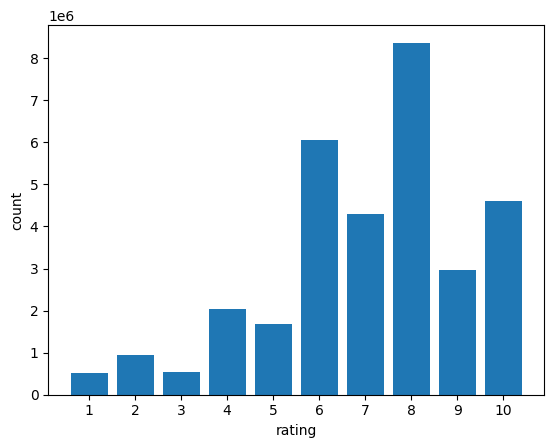

In [ ]:
counts = (
    movies_ratings.with_columns(pl.col("rating").cast(pl.Int32)).group_by("rating")
      .len()
      .sort("rating")
)

plt.bar(counts["rating"], counts["len"], width=0.8, align="center")
plt.xticks(list(range(1, 11)))
plt.xlabel("rating")
plt.ylabel("count")
plt.show()

In [ ]:
print(
  f"""
  max user id {movies_ratings["user_id"].max()}
  num unique user ids {movies_ratings["user_id"].unique().shape[0]}
  max item id {movies_ratings["item_id"].max()}
  num unique item ids {movies_ratings["item_id"].unique().shape[0]}
  """
)


  max user id 200948
  num unique user ids 200948
  max item id 29081098
  num unique item ids 84432
  


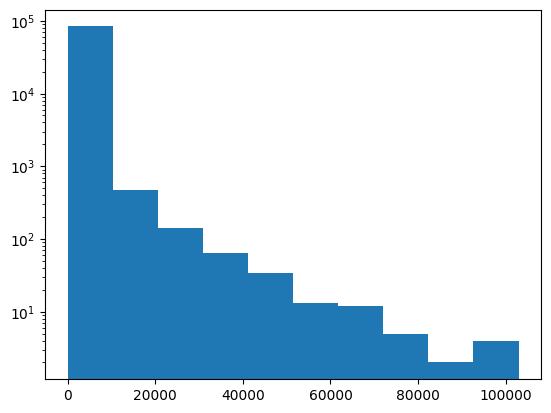

In [ ]:
count = movies_ratings.group_by(pl.col("item_id")).len()
plt.hist(count["len"].to_numpy())
plt.yscale("log")
plt.show()

<h2 style="color: rgb(46, 81, 162)">MyAnimeList Database 2020</h2>

Датасет с оценками Аниме от пользователей сайта MyAnimeList

[Dataset](https://www.kaggle.com/datasets/hernan4444/anime-recommendation-database-2020)

[MyAnimeList.net](https://myanimelist.net)

<img src="https://i.pinimg.com/originals/53/0b/16/530b16f27752dfbb67c7db8d7b6fae4c.jpg" width="400" />

### Загрузка датасета:

In [ ]:
download_and_extract(
    url="https://www.kaggle.com/api/v1/datasets/download/hernan4444/anime-recommendation-database-2020",
    filename="anime.zip",
)

anime.zip уже скачан, пропускаем загрузку


In [ ]:
anime = pl.read_csv(
    "anime.csv",
    schema_overrides={**{"Ranked": pl.Utf8, "Score": pl.Utf8}, **{f"Score-{i}": pl.Utf8 for i in range(1, 11)}},
)

anime = anime.with_columns(
    title=pl.when(pl.col("English name") == "Unknown").then(pl.col("Name")).otherwise(pl.col("English name"))
)

anime = anime.rename({"MAL_ID": "item_id"})
anime = anime.select(["item_id", "title"])


In [ ]:
anime_ratings = pl.read_csv("rating_complete.csv")
anime_ratings = anime_ratings.rename({"anime_id": "item_id"})
anime_ratings = anime_ratings.with_columns(pl.col("rating").cast(pl.Float64))
anime_ratings

user_id,item_id,rating
i64,i64,f64
0,430,9.0
0,1004,5.0
0,3010,7.0
0,570,7.0
0,2762,9.0
…,…,…
353404,502,8.0
353404,987,4.0
353404,225,8.0


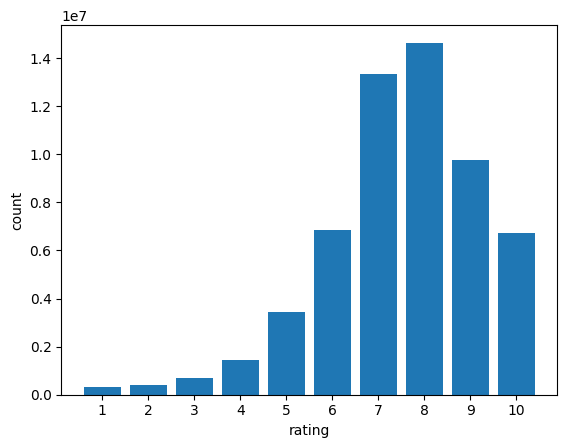

In [ ]:
counts = (
    anime_ratings.with_columns(pl.col("rating").cast(pl.Int32)).group_by("rating")
      .len()
      .sort("rating")
)

plt.bar(counts["rating"], counts["len"], width=0.8, align="center")
plt.xticks(list(range(1, 11)))
plt.xlabel("rating")
plt.ylabel("count")
plt.show()

In [ ]:
print(
  f"""
  max user id {anime_ratings["user_id"].max()}
  num unique user ids {anime_ratings["user_id"].unique().shape[0]}
  max item id {anime_ratings["item_id"].max()}
  num unique item ids {anime_ratings["item_id"].unique().shape[0]}
  """
)


  max user id 353404
  num unique user ids 310059
  max item id 48456
  num unique item ids 16872
  


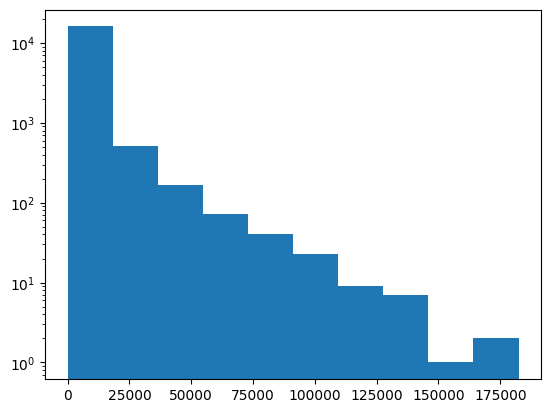

In [ ]:
count = anime_ratings.group_by(pl.col("item_id")).len()
plt.hist(count["len"].to_numpy())
plt.yscale("log")
plt.show()

## User-Item Interaction matrix

На одни и те же данные можно смотреть по-разному.
Всё зависит от того, какую интерпретацию мы в них выбираем**.

Тот же самый лог `(user_id, item_id, rating, timestamp)` можно воспринимать по-разному:

* как обычные табличные данные и соответственно работать с ней как мы привылки
* как **разреженную user–item матрицу**, где сразу становится заметна спарсовость задачи, проблема холодного старта и как следствие появляется естественная мотивация для факторизаций.
* представить взаимодействия как двудольный граф и решать задачу, применяя графовые подходы
* Саггрегировать взаимодействия для каждого пользователя и работать с пользовательской историей в виде последовательности

**Сегодня мы остановится на матричном представлении данных**


<img src="https://i.postimg.cc/X7x0gj4W/Screenshot-2026-02-07-at-19-18-46.png" width="700" />



### Посмотрим на наши данные

In [ ]:
def get_interaction_matrix(actions: pl.DataFrame) -> csr_matrix:
      id2user = np.array(actions["user_id"].unique())
      id2item = np.array(actions["item_id"].unique())
      user2id = {uid: idx for idx, uid in enumerate(id2user)}
      item2id = {uid: idx for idx, uid in enumerate(id2item)}

      rows = [user2id[i] for i in actions["user_id"]]
      cols = [item2id[i] for i in actions["item_id"]]
      # Binary interactions (ignore rating values)
      data = np.ones((actions["rating"].shape[0],))
      return csr_matrix((data, (rows, cols)), dtype=np.float32)

def plot_matrix(interaction_matrix: np.array, title: str):
  scale = interaction_matrix.shape[1] // interaction_matrix.shape[0]
  plt.figure(figsize=(int(scale) * 6, 6))
  plt.imshow(interaction_matrix, cmap="gray_r", interpolation="nearest")
  plt.title(title)
  plt.xlabel("Items")
  plt.ylabel("Users")
  plt.show()



In [ ]:
interaction_matrix = get_interaction_matrix(movies_ratings)

In [ ]:
print(f"IMDB Interaction matrix density: {100 * interaction_matrix.mean():.3f}%")

IMDB Interaction matrix density: 0.189%


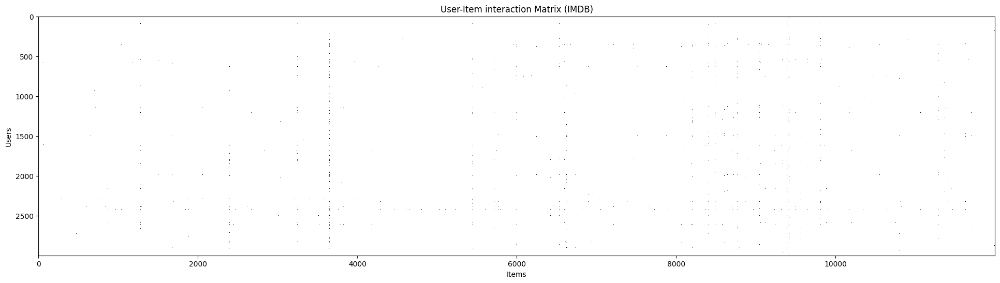

In [ ]:
# берем subsample матрицы так как вся матрица в dense представлении слишком большая

plot_matrix(interaction_matrix[:3000, :12000].toarray(), "User-Item interaction Matrix (IMDB)")

In [ ]:
interaction_matrix = get_interaction_matrix(anime_ratings)


In [ ]:
print(f"Anime interaction matrix density: {100 * interaction_matrix.mean():.3f}%")

Anime interaction matrix density: 1.102%


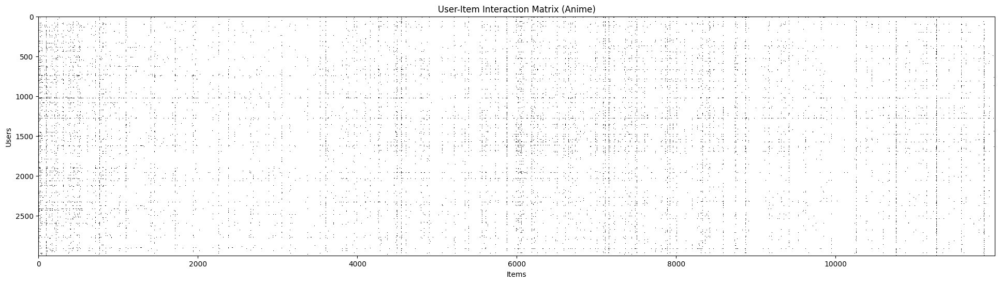

In [ ]:
plot_matrix(interaction_matrix[:3000, :12000].toarray(), "User-Item Interaction Matrix (Anime)")

## Выбор датасета:

In [ ]:
# можно выбрать любой и дальнейший код будет работать с этим датасетом

DATASET_TYPE = "MOVIES"  # "MOVIES" или "ANIME"

datasets = {
    "MOVIES": (movies_ratings, movies),
    "ANIME": (anime_ratings, anime),
}

ratings, items = datasets[DATASET_TYPE]

## Загрузка постеров:

In [ ]:
class PosterDisplay:
    def __init__(self, dataset_type: str):
        self.dataset_type = dataset_type.upper()

        self.headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7)"}

    def _get_poster_url(self, item_id):
        try:
            if self.dataset_type == "MOVIES":
                imdb_id = f"tt{int(item_id):07d}"
                # shortcut: публичный lookup IMDb не документирован; при изменении API замените источник постеров.
                url = f"https://v2.sg.media-imdb.com/suggestion/t/{imdb_id}.json"
                response = requests.get(url, headers=self.headers, timeout=10)
                response.raise_for_status()
                for title in response.json().get("d", []):
                    if title.get("id") == imdb_id:
                        poster_url = (title.get("i") or {}).get("imageUrl")
                        if poster_url:
                            return poster_url
                print(f"No poster found for {self.dataset_type} ID {item_id}")
                return None

            url = f"https://myanimelist.net/anime/{item_id}/"
            response = requests.get(url, headers=self.headers, timeout=10)
            response.raise_for_status()

            soup = BeautifulSoup(response.text, "html.parser")

            # Поиск элемента с изображением
            poster_element = soup.find("img", {"itemprop": "image"})

            if not poster_element:
                print(f"No poster found for {self.dataset_type} ID {item_id}")
                return None

            return poster_element.get("data-src")

        except Exception as e:
            print(f"Error fetching {self.dataset_type} URL {item_id}: {e}")
            return None

    def _load_poster(self, row):
        item_id, title = row[0], row[1]
        try:
            poster_url = self._get_poster_url(item_id)

            if not poster_url:
                return None, None

            response = requests.get(poster_url, timeout=10)
            response.raise_for_status()

        except Exception as e:
            print(f"Error loading poster for '{title}': {e}")
            return None, None

        return Image.open(BytesIO(response.content)), title

    def show_posters(self, data):
        data = data[["item_id", "title"]]
        _, axes = plt.subplots(2, 5, figsize=(20, 8))
        rows = [row for row in data.iter_rows()]

        with ThreadPoolExecutor(max_workers=10) as executor:
            results = list(executor.map(self._load_poster, rows))

        for idx, (img, title) in enumerate(results):
            ax = axes[idx // 5, idx % 5]
            if img and title:
                ax.imshow(img)
                ax.set_title(title)
            else:
                ax.set_title("Image not available")
            ax.axis("off")

        plt.tight_layout()
        plt.show()

## 10 самых оценённых фильмов

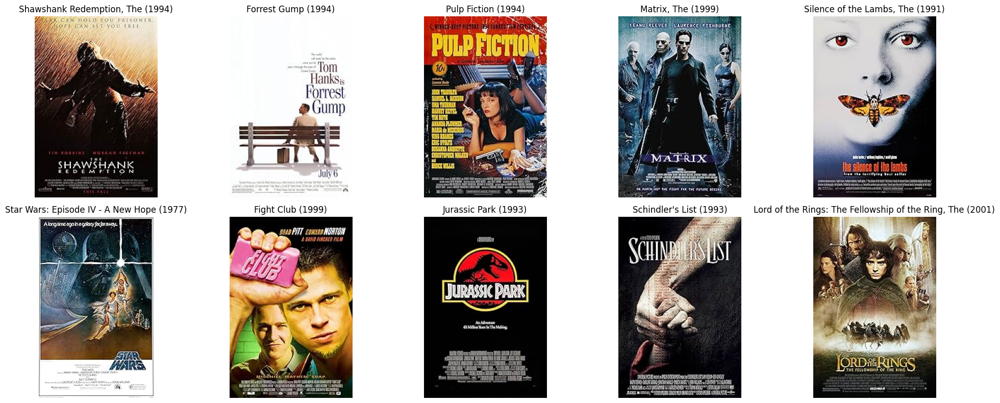

In [ ]:
top_10 = ratings.group_by("item_id").agg(pl.len()).join(items, on="item_id").sort("len", descending=True).head(10)

if DATASET_TYPE == "ANIME":
    assert top_10[0]["item_id"].item() == 1535
    assert top_10[0]["title"].item() == "Death Note"
else:
    assert top_10[0]["item_id"].item() == 111161
    assert top_10[0]["title"].item() == "Shawshank Redemption, The (1994)"

assert top_10.shape[0] == 10

display = PosterDisplay(DATASET_TYPE)
display.show_posters(top_10)

## Сплитим датасет на трейн и тест:

*Исходник https://arxiv.org/pdf/2507.16289*
<img src="https://i.postimg.cc/xqDYMWgg/Screenshot-2026-02-07-at-18-02-18.png" width="2000"/>

Для упрощения сделаем random split (но не делайте так для реальных задач)

- Отфильтруем в датасете пользователей и айтемы с количеством взаимодействий меньше 20
- В тест отправим 10 случайных взаимодействий
- В трейн отправляем всё остальное

In [ ]:
def train_test_split(
    ratings: pl.DataFrame,
    sample_size: int | None = None,
    min_interactions_count: int = 20,
    items_for_test: int = 10,
) -> tuple[pl.DataFrame, pl.DataFrame]:
    ratings = ratings.filter(pl.col("rating") >= 7)
    ratings = ratings.sort(pl.col("user_id").hash())[:sample_size]

    # shortcut: после одного прохода числа взаимодействий могут стать ниже порога
    ratings = ratings.filter(
        pl.len().over("user_id") >= min_interactions_count,
        pl.len().over("item_id") >= min_interactions_count,
    )

    # После перемешивания первые items_for_test оценок каждого пользователя идут в тест.
    ratings = ratings.sample(fraction=1.0, shuffle=True, seed=42).with_columns(
        row_n=pl.int_range(pl.len()).over("user_id"),
    )
    train = ratings.filter(pl.col("row_n") >= items_for_test).drop("row_n")
    test = ratings.filter(pl.col("row_n") < items_for_test).drop("row_n")
    return train, test

In [ ]:
SAMPLE_SIZE = 3_000_000

train, test = train_test_split(ratings, SAMPLE_SIZE)

train

user_id,item_id,rating
i64,i64,f64
162621,250797,7.0
162621,1182345,8.0
162621,415978,8.0
162621,465551,8.0
95987,993842,8.0
…,…,…
124306,86984,9.0
109361,13442,8.0
90716,1860357,7.0


## Добавляем ваши оценки в датасет:

1) В YOUR_ITEM_IDS добавьте ID фильмов или аниме.
Найти их можно на сайтах в адресной строке

**Примеры:**
- https://www.imdb.com/title/tt0099685 - id=99685 (без нулей вначале)
- https://myanimelist.net/anime/32182 - id=32182

2) В YOUR_RATINGS добавьте свои оценки для указанных фильмов

**ВНИМАНИЕ:**
- Для фильмов оценки от 1 до 10 с шагом в 1 (исходные оценки MovieLens умножены на 2)
- Для аниме оценки от 1 до 10 с шагом в 1

In [ ]:
YOUR_USER_ID = -1

DATASET2USER = {
    "MOVIES": {
        "item_ids": [332280, 243155, 3783958,], # Дневник Памяти, Бриджит Джонс, Ла-Ла Ленд
        "ratings": [10.0, 10.0, 10.0],
        "item_example": 88763 # 7888964 - Никто, 88763 - Назад в будущее, 3783958 - Ла-Ла Ленд

    },
    "ANIME": {
        "item_ids": [32182, 185, 199],
        "ratings": [10.0, 10.0, 10.0],
        "item_example": 30276, # One Punch Man
    }
}

# Пример для фильмов:
YOUR_ITEM_IDS = DATASET2USER[DATASET_TYPE]["item_ids"]
YOUR_RATINGS = DATASET2USER[DATASET_TYPE]["ratings"]

ITEM_EXAMPLE = DATASET2USER[DATASET_TYPE]["item_example"]


your_profile_df = pl.DataFrame(
    {
      "user_id": [YOUR_USER_ID] * len(YOUR_ITEM_IDS),
      "item_id": YOUR_ITEM_IDS,
      "rating": YOUR_RATINGS,
    },
)

train_with_you = pl.concat([your_profile_df, train])
train_with_you

user_id,item_id,rating
i64,i64,f64
-1,332280,10.0
-1,243155,10.0
-1,3783958,10.0
162621,250797,7.0
162621,1182345,8.0
…,…,…
124306,86984,9.0
109361,13442,8.0
90716,1860357,7.0


## Базовый класс рекомендера:

Базовый класс, от которого будем наследовать наши алгоритмы

In [ ]:
class BaseRecommender:
    def __init__(self, actions: pl.DataFrame):
        self.id2user = np.array(actions["user_id"].unique())
        self.id2item = np.array(actions["item_id"].unique())
        self.user2id = {uid: idx for idx, uid in enumerate(self.id2user)}
        self.item2id = {uid: idx for idx, uid in enumerate(self.id2item)}

        rows = [self.user2id[i] for i in actions["user_id"]]
        cols = [self.item2id[i] for i in actions["item_id"]]
        data = actions["rating"].to_numpy()

        self.ratings_matrix = csr_matrix((data, (rows, cols)), dtype=np.float32)

        self.interactions_matrix = csr_matrix((np.ones((data.shape[0])), (rows, cols)), dtype=np.float32)

        self.row_lengths = np.array(self.interactions_matrix.count_nonzero(axis=1)).ravel()
        self.col_lengths = np.array(self.interactions_matrix.count_nonzero(axis=0)).ravel()

    def _get_user_items(self, user_idx: int):
        return [self.id2item[idx] for idx in self.ratings_matrix[user_idx].indices]

    def recommend_for_users(self, user_id, k: int = 10):
        raise NotImplementedError

    def find_similar_items(self, item_id, k: int = 10):
        raise NotImplementedError

## Коэффициент Жаккара:

Реализуем рекомендации на основе близости Жаккара

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$
<table>
  <tbody>
    <tr>
      <td><img src="https://upload.wikimedia.org/wikipedia/commons/1/1f/Intersection_of_sets_A_and_B.svg" alt="Intersection of sets A and B" width="200" /></td>
      <td><img src="https://upload.wikimedia.org/wikipedia/commons/e/ee/Union_of_sets_A_and_B.svg" alt="Union of sets A and B" width="200" /></td>
    </tr>
  </tbody>
</table>


- В функции find_similar_items будем искать айтемы с самым высоким коэффициентом Жаккара в текущему
- В функции recommend_for_users:
    - Ищем похожих пользователей по коэ-ту Жаккара
    - Берём их взаимодействия и формируем из них рекомендации к пользователю

In [ ]:
class JaccardRecommender(BaseRecommender):
    def __init__(self, actions, eps: float = 1e-4):
        super().__init__(actions)
        self.eps = eps

    def _batch_jaccard_similarity(self, target_indices: np.ndarray) -> np.ndarray:

        # |A ^ B| / |A v B| = | A ^ B | / (|A| v |B| - |A ^ B|)

        target_vectors = self.interactions_matrix[target_indices]

        intersections = (target_vectors @ self.interactions_matrix.T).toarray()

        unions = self.row_lengths[target_indices][:, None] + self.row_lengths[None, :] - intersections
        similarities = intersections / (unions + self.eps)

        return similarities

    def recommend_for_users(self, user_ids: list, k: int = 10) -> dict:
        recommendations = {}
        valid_user_ids = [uid for uid in user_ids if uid in self.user2id]
        user_indices = np.array([self.user2id[uid] for uid in valid_user_ids])

        if len(user_indices) == 0:
            return {}

        sim_matrix = self._batch_jaccard_similarity(user_indices)
        sim_matrix[np.arange(len(user_indices)), user_indices] = -np.inf

        # Поиск топ-k соседей
        top_sim_users = np.argpartition(-sim_matrix, k, axis=1)[:, :k]

        for i, (uid, u_idx) in enumerate(zip(valid_user_ids, user_indices)):
            seen_items = set(self._get_user_items(u_idx))
            item_scores = defaultdict(float)

            for neighbor_idx in top_sim_users[i]:
                if neighbor_idx == u_idx:
                    continue
                for item in self._get_user_items(neighbor_idx):
                    if item not in seen_items:
                        item_scores[item] += sim_matrix[i, neighbor_idx]

            top_items = sorted(item_scores, key=lambda x: (-item_scores[x], x))[:k]
            recommendations[uid] = top_items

        return recommendations

    def find_similar_items(self, item_id: int, k: int = 10):
        if item_id not in self.item2id:
            return []

        item_idx = self.item2id[item_id]
        item_vector = self.interactions_matrix[:, item_idx]

        intersections = (item_vector.T @ self.interactions_matrix).toarray().flatten()
        unions = self.col_lengths[item_idx] + self.col_lengths - intersections

        similarities = intersections / (unions + self.eps)

        similarities[item_idx] = -1

        top_indices = np.argsort(-similarities)[:k]
        return [self.id2item[i] for i in top_indices]

In [ ]:
jaccard = JaccardRecommender(train_with_you)

## Cмотрим на похожие фильмы:

In [ ]:
def show_similar_items(item_id, algorithm: BaseRecommender, k: int = 10):
    recommendations = algorithm.find_similar_items(item_id, k)
    recommendations = pl.DataFrame({"item_id": recommendations}).with_row_index("target_order")
    recommendations = items.join(recommendations, on="item_id", how="inner").sort("target_order")
    display.show_posters(recommendations)

def show_recommendations(user_id, algorithm: BaseRecommender, k: int = 10):
    recommendations = algorithm.recommend_for_users([user_id], k)
    recommendations = pl.DataFrame({"item_id": recommendations[user_id]}).with_row_index("target_order")
    recommendations = items.join(recommendations, on="item_id", how="inner").sort("target_order")
    display.show_posters(recommendations)


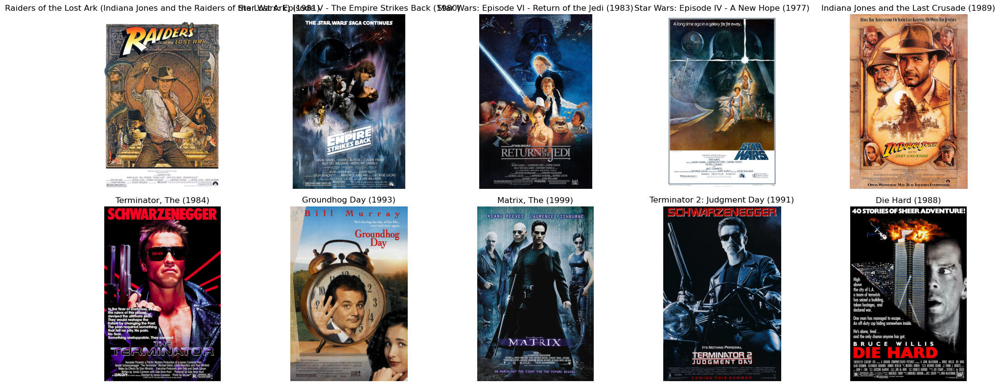

In [ ]:
show_similar_items(ITEM_EXAMPLE, jaccard, 10)

## Персональные рекомендации для вас:

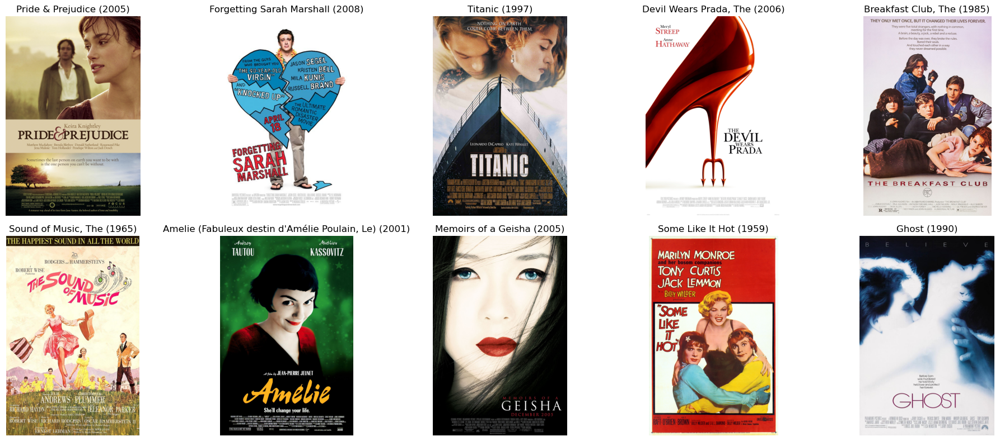

In [ ]:
show_recommendations(YOUR_USER_ID, jaccard, 10)

# Precision@k: Метрика точности рекомендаций

$$\text{Precision@k} = \frac{\text{Количество релевантных элементов}}{K}$$

- Одна из самых простых метрик для оценки точности рекомендаций - Precision@k.
- Представляет из себя долю точно предсказанных элементов.
- Мы будем использовать Precision@10, т.к. оставили в тестовом наборе данных по 10 айтемов для каждого пользователя.

In [ ]:
from statistics import mean


def calculate_precision_at_k(model: BaseRecommender, test_df: pl.DataFrame, k: int = 10) -> float:
    test_users = test_df.group_by("user_id").agg(pl.col("item_id")).to_dict(as_series=False)

    test_users = dict(zip(test_users["user_id"], test_users["item_id"]))

    # Оставляем только тех пользователей, которых модель видела
    valid_users = [uid for uid in test_users if uid in model.user2id]

    batch_recommendations = model.recommend_for_users(valid_users, k=k)

    # Iterate only over valid_users: cold users are not in batch_recommendations
    precisions = [len(set(batch_recommendations[user_id]) & set(test_users[user_id])) for user_id in valid_users]

    if not precisions:
        return 0.0

    precision = mean(precisions) / k

    return precision

In [ ]:
# Для быстрой оценки выбираем до 1000 пользователей со всей их тестовой историей.
evaluation_users = (
    test.select("user_id").unique().sort("user_id")
    .sample(fraction=1.0, shuffle=True, seed=42)
    .head(1000)
)
evaluation_test = test.join(evaluation_users, on="user_id", how="semi")

jaccard_score = calculate_precision_at_k(jaccard, evaluation_test)
print(f"Jaccard Precision@10: {jaccard_score:.4f}")

Jaccard Precision@10: 0.1454


# NPMI (Normalized Pointwise Mutual Information)

- PMI — точечная взаимная информация:

$$\text{PMI}(X, Y) = \log \frac{P(X, Y)}{P(X) \cdot P(Y)}$$

- Нормализованная точечная взаимная информация (NPMI) вычисляется по формуле:

$$\text{NPMI}(X, Y) = \frac{\text{PMI}(X, Y)}{-\log P(X, Y)}$$

$$\text{NPMI}(X, Y) = \frac{\log \left( \frac{P(X, Y)}{P(X) \cdot P(Y)} \right)}{-\log P(X, Y)}$$

- Поскольку мы явно делим на абсолютные вероятности, мы напрямую штрафуем популярные айтемы.
- Это значительно уменьшает шанс порекомендовать что-то популярное.

In [ ]:
class NPMIRecommender(BaseRecommender):
    def __init__(self, actions: pl.DataFrame, top_k: int = 10):
        super().__init__(actions)
        self.top_k = top_k  # Количество сохраняемых похожих элементов
        self.top_similar: dict[int, list[tuple[int, float]]] = self._precompute_top_similar()

    def _precompute_top_similar(self) -> dict[int, list[tuple[int, float]]]:
        """Предрасчет топовых похожих фильмов для каждого фильма"""
        item_counts = self.col_lengths
        total_users = self.interactions_matrix.shape[0]

        p_i = item_counts / total_users
        p_ij = self.interactions_matrix.T.dot(self.interactions_matrix).toarray() / total_users # (num_items, num_items)

        npmi = np.full(p_ij.shape, -1.0)
        observed = (p_ij > 0) & (p_ij < 1)
        pmi = np.log(p_ij[observed] / (p_i[:, None] * p_i[None, :])[observed])
        npmi[observed] = pmi / -np.log(p_ij[observed])
        npmi[p_ij == 1] = 1.0

        np.fill_diagonal(npmi, -np.inf)

        top_indices = np.argsort(-npmi, axis=1)[:, : self.top_k]

        top_similar = {}
        for item_idx in range(len(self.id2item)):
            top_items = top_indices[item_idx, :].ravel()
            top_similar[item_idx] = list(zip(top_items, npmi[item_idx, top_items]))

        return top_similar

    def recommend_for_users(self, user_ids: list, k: int = 10) -> dict:
        """Быстрые рекомендации через предрасчитанные топы"""
        recommendations = {}

        for uid in user_ids:
            if uid not in self.user2id:
                continue

            user_idx = self.user2id[uid]
            seen_items = set(self._get_user_items(user_idx))
            item_scores = defaultdict(float)

            # Агрегация по предрасчитанным топам
            for item in seen_items:
                item_idx = self.item2id[item]
                for sim_item_idx, score in self.top_similar.get(item_idx, []):
                    sim_item = self.id2item[sim_item_idx]
                    if sim_item not in seen_items:
                        item_scores[sim_item] += score

            # Сортировка и выбор топ-K
            sorted_items = sorted(item_scores.items(), key=lambda x: (-x[1], x[0]))
            recommendations[uid] = [item for item, _ in sorted_items[:k]]

        return recommendations

    def find_similar_items(self, item_id, k: int = 10):
        """Быстрый поиск похожих элементов из предрасчитанных"""
        if item_id not in self.item2id:
            return []

        item_idx = self.item2id[item_id]

        return [self.id2item[sim_idx] for sim_idx, _ in self.top_similar.get(item_idx, [])[:k]]

In [ ]:
npmi = NPMIRecommender(train_with_you)

## Cмотрим на похожие фильмы:

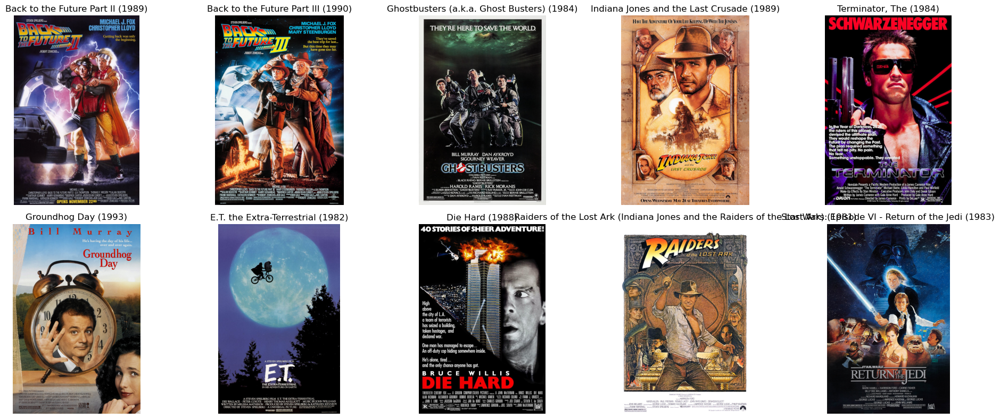

In [ ]:
show_similar_items(ITEM_EXAMPLE, npmi, 10)

## Персональные рекомендации для вас:

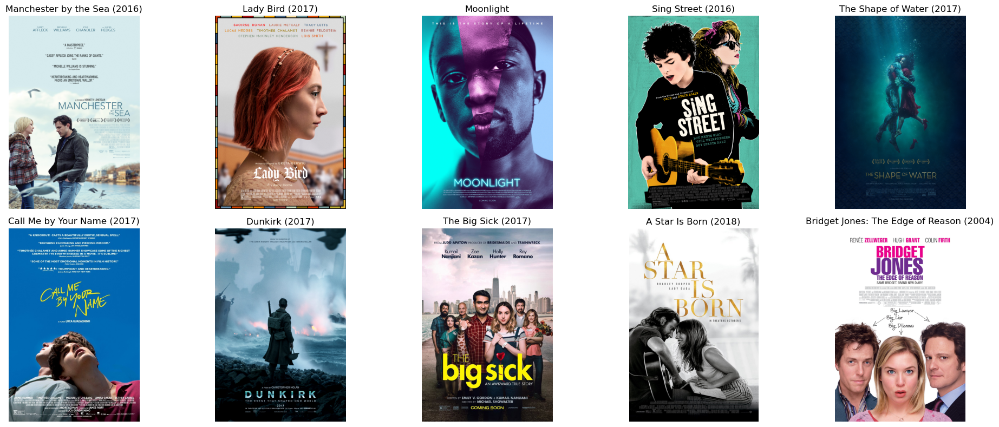

In [ ]:
show_recommendations(YOUR_USER_ID, npmi, 10)

## Точность NPMI рекомендера:

In [ ]:
npmi_score = calculate_precision_at_k(npmi, evaluation_test)
print(f"NPMI Precision@10: {npmi_score:.4f}")

NPMI Precision@10: 0.0952


# SVD

<img src="https://miro.medium.com/v2/1*3AKeocoYapITWR9ssGTHdQ.jpeg" width="600" />

In [ ]:
from scipy.sparse.linalg import svds


class SVDRecommender(BaseRecommender):
    def __init__(self, actions: pl.DataFrame, n_factors=128):
        super().__init__(actions)

        self.U, self.S, self.Vt = svds(self.ratings_matrix, k=n_factors)

        self.S = np.diag(self.S)

        # Precompute S-weighted item embeddings and their norms for cosine similarity
        self.item_embeddings = self.S @ self.Vt  # (k, n_items)
        self.item_norms = np.linalg.norm(self.item_embeddings, axis=0)  # (n_items,)

    def find_similar_items(self, item_id: int, k: int = 10) -> List[str]:
        """Поиск похожих элементов через косинусную схожесть"""
        if item_id not in self.item2id:
            return []

        item_idx = self.item2id[item_id]

        item_vec = self.item_embeddings[:, item_idx]  # (k,)

        scores = item_vec @ self.item_embeddings  # (n_items,)
        scores = scores / (self.item_norms * self.item_norms[item_idx] + 1e-8)

        scores[item_idx] = -np.inf

        topk = np.argsort(-scores)[:k]

        return [self.id2item[idx] for idx in topk]

    def recommend_for_users(self, user_ids: List[str], k: int = 10) -> Dict[str, List[str]]:
        """Рекомендации для батча пользователей"""
        valid_users = []
        user_indices = []

        # Фильтрация валидных пользователей
        for uid in user_ids:
            if uid in self.user2id:
                valid_users.append(uid)
                user_indices.append(self.user2id[uid])

        if not valid_users:
            return {}

        user_indices = np.array(user_indices)

        # Расчет оценок
        user_factors = self.U[user_indices]

        scores_matrix = user_factors @ self.item_embeddings  # (n_batch, n_items)

        viewed_mask = self.interactions_matrix[user_indices].toarray().astype(bool)
        scores_matrix[viewed_mask] = -np.inf

        recommendations = {}
        for i, uid in enumerate(valid_users):
            scores = scores_matrix[i]
            topk = np.argsort(-scores)[:k]
            recommendations[uid] = [self.id2item[idx] for idx in topk]

        return recommendations


In [ ]:
svd = SVDRecommender(train_with_you, n_factors=32)

## Cмотрим на похожие фильмы:

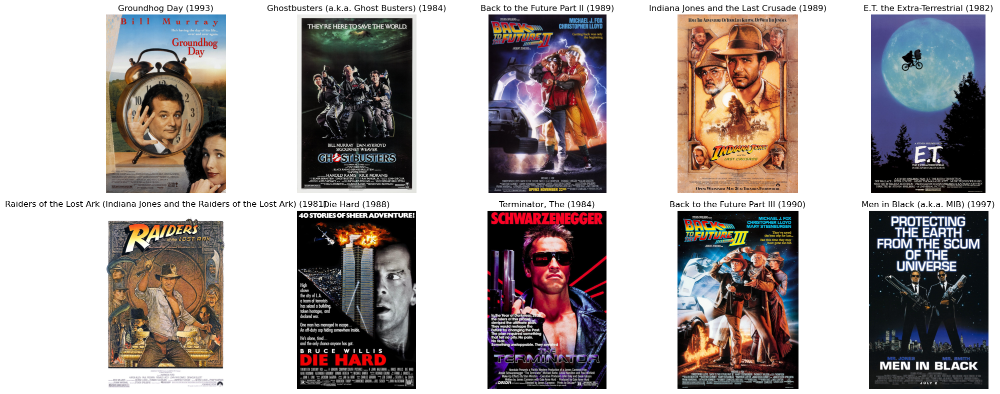

In [ ]:
show_similar_items(ITEM_EXAMPLE, svd, 10)

## Персональные рекомендации вас:

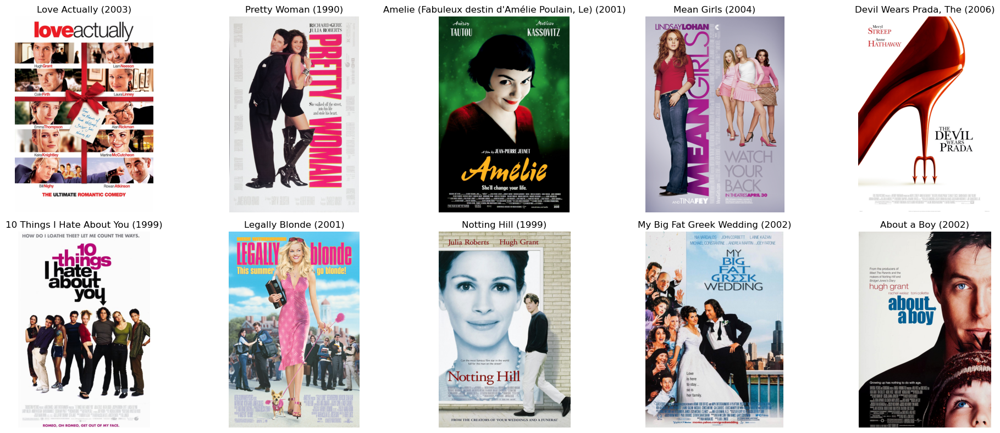

In [ ]:
show_recommendations(YOUR_USER_ID, svd, 10)

In [ ]:
svd_score = calculate_precision_at_k(svd, evaluation_test)
print(f"SVD Precision@10: {svd_score:.4f}")

SVD Precision@10: 0.1829


## Итог

In [ ]:
print(f"Jaccard Precision@10: {jaccard_score:.4f}")
print(f"NPMI Precision@10: {npmi_score:.4f}")
print(f"SVD Precision@10: {svd_score:.4f}")


Jaccard Precision@10: 0.1454
NPMI Precision@10: 0.0952
SVD Precision@10: 0.1829


## Посмотрим на пространство фильмов:

In [ ]:
order_df = pl.DataFrame({"item_id": svd.id2item}).with_row_index("target_order")
names = items.join(order_df, on="item_id", how="right").sort("target_order")["title"]

log_dir = "logs/imdb-example/"

if not os.path.exists(log_dir):
    os.makedirs(log_dir)

with open(os.path.join(log_dir, "metadata.tsv"), "w") as f:
    f.writelines([f"{n}\n" for n in names])

import tensorflow as tf # noqa


weights = tf.Variable(svd.Vt.T)
checkpoint = tf.train.Checkpoint(embedding=weights)
checkpoint.save(os.path.join(log_dir, "embedding.ckpt"))

config = projector.ProjectorConfig()
embedding = config.embeddings.add()
embedding.tensor_name = "embedding/.ATTRIBUTES/VARIABLE_VALUE"
embedding.metadata_path = "metadata.tsv"
projector.visualize_embeddings(log_dir, config)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs/imdb-example/